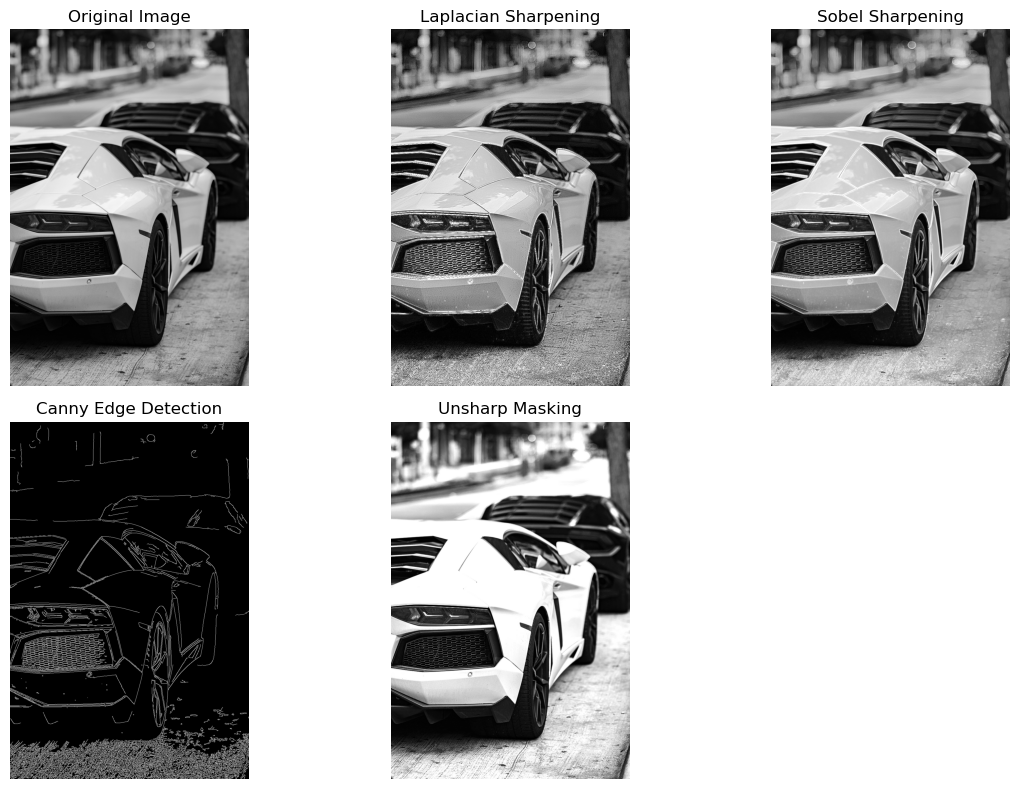

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread('car.jpg', cv2.IMREAD_GRAYSCALE)

if img is None:
    print("Image not found!")
    exit()

# 1. Laplacian Filter
lap = cv2.Laplacian(img, cv2.CV_64F, ksize=3)
sharp_lap = cv2.convertScaleAbs(img.astype(np.float64) - lap)


# 2. Sobel Operator
gx = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3)
gy = cv2.Sobel(img, cv2.CV_64F, 0, 1, ksize=3)

gradient = cv2.magnitude(gx, gy)
gradient = cv2.convertScaleAbs(gradient)

sharp_sobel = cv2.addWeighted(img, 1, gradient, 0.5, 0)


# Canny Edge Detector
edges = cv2.Canny(img, 50, 150)


# 3. Unsharp Masking
gaussian = cv2.GaussianBlur(img, (5, 5), 3)

mask = cv2.subtract(img, gaussian)

sharp_unsharp = cv2.addWeighted(img, 1.5, mask, 1, 0)


# Display results
plt.figure(figsize=(12, 8))

plt.subplot(2, 3, 1)
plt.imshow(img, cmap='gray')
plt.title("Original Image")
plt.axis('off')

plt.subplot(2, 3, 2)
plt.imshow(sharp_lap, cmap='gray')
plt.title("Laplacian Sharpening")
plt.axis('off')

plt.subplot(2, 3, 3)
plt.imshow(sharp_sobel, cmap='gray')
plt.title("Sobel Sharpening")
plt.axis('off')

plt.subplot(2, 3, 4)
plt.imshow(edges, cmap='gray')
plt.title("Canny Edge Detection")
plt.axis('off')

plt.subplot(2, 3, 5)
plt.imshow(sharp_unsharp, cmap='gray')
plt.title("Unsharp Masking")
plt.axis('off')

plt.tight_layout()
plt.show()